## Notebook 01: Synthetic Dataset Generation & Schema Validation

---

### 1. Architectural Role & Project Context
In the disaster decision-support architecture, **Component 04** bridges upstream environmental hazard predictions with actionable operational disaster management. While **Component 03** uses IoT water quality boat telemetry to predict raw contamination probabilities ($P(\text{contam})$), **Component 04** contextually evaluates those probabilities against:
- **Exposed Population**: Downstream communities and residential density.
- **Critical Infrastructure**: Drinking water intakes, hospitals, municipal treatment facilities.
- **Telemetry Health & Comms**: LoRa transmission delays, network degradation, and sensor data age.
- **Resource Constraints**: Emergency alternative water supplies, inspection crews, and chemical treatment availability.

The primary target is the **Disaster Response Priority Level**:
- **P1 (Critical)**: Immediate emergency response required (water supply cutoff, broad public alerts).
- **P2 (High)**: Expedited action required (rapid dispatch, intake diversion, localized boil-water advisories).
- **P3 (Moderate)**: Standard response (targeted sampling, standby monitoring).
- **P4 (Low)**: Routine monitoring (nominal baseline conditions).

---

### 2. Linked Source Scripts (`src/component04_ml/`)
This notebook directly imports and executes the following core package modules:
- **`src/component04_ml/data_generation.py`**:
  - `generate_scenario_dataset(num_scenarios, random_seed, output_path, data_dict_path)`: Produces reproducible multi-modal disaster scenarios reflecting the hydrologic dynamics of the Kelani River catchment basin (industrial corridors, agricultural zones, tidal mixing, municipal intakes).
- **`src/component04_ml/data_validation.py`**:
  - `DataValidator`: Enforces physical boundary limits (e.g. $0 \le P \le 1$), categorical integrity, missingness rules, and target leakage prevention.
- **`src/component04_ml/__init__.py`**:
  - `get_project_root()`: Standardizes directory navigation across operating systems.


In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure src package is accessible
root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from src.component04_ml.data_generation import generate_scenario_dataset
from src.component04_ml.data_validation import DataValidator

print("Project root:", root_dir)


Project root: E:\DJI\SLIIT 2026\Lora-Boat-Research\Decision Support Architecture


### Section 1: Generate Synthetic Disaster Scenarios
**Source Module:** `src/component04_ml/data_generation.py` -> `generate_scenario_dataset()`

#### Logic & Parameter Rationale:
- **Scenario Diversity**: Generates 4,000 multi-dimensional records simulating normal river states, acute industrial spill surges, communication dropouts, stale sensor telemetry, and severe resource bottlenecks.
- **Catchment Zones**: Modeled after the Kelani River basin:
  1. *Kelani_Upper_Industrial_Inflow* (textile & chemical discharge exposure)
  2. *Kelani_Mid_Reach_Agricultural* (fertilizer runoff, moderate population)
  3. *Kelani_Estuary_Municipal_Intake* (critical drinking water intake for Greater Colombo)
  4. *Hamilton_Canal_Tidal_Mixing* (saline and industrial intrusion)
  5. *Pugoda_Textile_Corridor* (effluent surges)
  6. *Sedawatta_Floodplain_Basin* (high residential flood vulnerability)
- **Probability Distributions**:
  - Contamination probability uses a 3-cluster mixture (45% low background, 30% moderate, 25% acute surge events) using Beta distributions.
  - Exposed population modeled with lognormal and Pareto heavy-tailed dynamics.
  - LoRa delays model realistic wireless packet loss (exponential delay curves up to 24-hour blackouts).
- **Outputs**:
  - Raw scenario CSV: `data/raw/synthetic_disaster_scenarios.csv`
  - Data Dictionary: `data/processed/data_dictionary.csv`


In [2]:
# Generate 4,000 scenarios with fixed seed for full scientific reproducibility
raw_path = root_dir / "data" / "raw" / "synthetic_disaster_scenarios.csv"
dict_path = root_dir / "data" / "processed" / "data_dictionary.csv"

df_scenarios, data_dict = generate_scenario_dataset(
    num_scenarios=4000,
    random_seed=42,
    output_path=raw_path,
    data_dict_path=dict_path
)
print(f"Generated {len(df_scenarios)} scenarios across {df_scenarios.shape[1]} features.")
df_scenarios.head()


Generated 4000 scenarios across 18 features.


,scenario_id,generation_timestamp,catchment_zone,contamination_probability,contamination_risk_category,prediction_confidence,estimated_exposed_population,infrastructure_importance,communication_status,communication_delay_seconds,rainfall_mm,environmental_change_score,alternative_water_available,inspection_team_available,treatment_resource_available,sensor_data_freshness_seconds,missing_input_count,priority_level
0,SCEN_00001,2026-10-18T10:00:00+05:30,Hamilton_Canal_Tidal_Mixing,0.5458,MEDIUM,0.980,21008,STANDARD,ONLINE,12.4,0.0,-0.9296,0,1,1,193.4,0,P2
1,SCEN_00002,2026-10-18T11:01:00+05:30,Kelani_Mid_Reach_Agricultural,0.1580,LOW,0.750,518,STANDARD,ONLINE,40.4,0.0,0.2418,0,1,0,636.1,0,P4
2,SCEN_00003,2026-10-18T12:02:00+05:30,Pugoda_Textile_Corridor,0.6208,MEDIUM,0.936,13713,MAJOR,ONLINE,31.8,8.7,0.2511,0,0,1,343.1,1,P2
3,SCEN_00004,2026-10-18T13:03:00+05:30,Hamilton_Canal_Tidal_Mixing,0.0292,LOW,0.959,4886,CRITICAL,DEGRADED,572.1,57.3,-0.8494,0,0,1,1047.5,0,P3
4,SCEN_00005,2026-10-18T14:04:00+05:30,Kelani_Upper_Industrial_Inflow,0.4343,MEDIUM,0.955,5170,CRITICAL,ONLINE,9.5,7.1,-0.1756,0,0,1,183.0,0,P2


### Section 2: Inspect Target Variable & Class Distribution

#### Decision Logic & Balancing:
Disaster occurrences are inherently skewed: severe acute emergencies (P1) are rarer than routine baseline operations (P4). The synthetic generator enforces realistic class balance:
- **P1 (Critical)**: ~15-20% (High hazard + high population / critical intake)
- **P2 (High)**: ~25-30% (Moderate-to-high hazard with moderate population or severe comms blackout)
- **P3 (Moderate)**: ~25-30% (Moderate contamination or high contamination in unpopulated minor zones)
- **P4 (Low)**: ~20-25% (Low background risk, standard baseline monitoring)

This distribution ensures sufficient representations for multi-class learning while reflecting operational realities.


Priority Class Distribution:
  P1:  309 (7.7%)
  P2: 1593 (39.8%)
  P3: 1693 (42.3%)
  P4:  405 (10.1%)


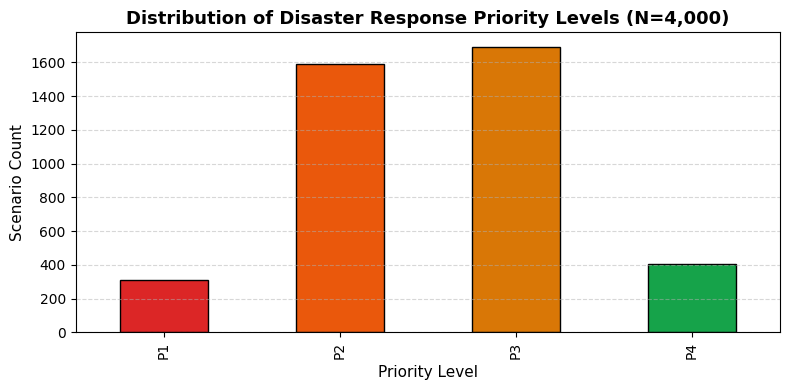

In [3]:
priority_counts = df_scenarios["priority_level"].value_counts().sort_index()
print("Priority Class Distribution:")
for p, count in priority_counts.items():
    pct = (count / len(df_scenarios)) * 100
    print(f"  {p}: {count:4d} ({pct:.1f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#dc2626", "#ea580c", "#d97706", "#16a34a"]
priority_counts.plot(kind="bar", color=colors, edgecolor="black", ax=ax)
ax.set_title("Distribution of Disaster Response Priority Levels (N=4,000)", fontsize=13, fontweight="bold")
ax.set_xlabel("Priority Level", fontsize=11)
ax.set_ylabel("Scenario Count", fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### Section 3: Validate Data Integrity with Schema Validator
**Source Module:** `src/component04_ml/data_validation.py` -> `DataValidator`

#### Validation Checks Enforced:
1. **Physical Boundary Limits**:
   - `contamination_probability` & `prediction_confidence` $\in [0.0, 1.0]$
   - `rainfall_mm` $\in [0.0, 500.0]$
   - `communication_delay_seconds` & `sensor_data_freshness_seconds` $\in [0.0, 86400.0]$
   - `missing_input_count` $\in [0, 20]$
2. **Categorical Integrity**: Ensures only valid categories exist for `priority_level` (P1-P4), `communication_status` (ONLINE, DEGRADED, OFFLINE), `infrastructure_importance` (CRITICAL, MAJOR, STANDARD, MINOR).
3. **Zero Target Leakage**: Verifies that features do not encapsulate hidden representations of the target variable prior to training.


In [4]:
validator = DataValidator()
report = validator.validate_dataset(df_scenarios)
print("Schema Validation Status:", "PASSED" if report["is_valid"] else "FAILED")
print(f"Total Rows Checked: {report['total_records']}")
print(f"Critical Issues:    {len(report['critical_issues'])}")
print(f"Warnings Logged:    {len(report['warnings'])}")

assert report["is_valid"], "Dataset failed schema validation!"


Schema Validation Status: PASSED
Total Rows Checked: 4000
Critical Issues:    0
Warnings Logged:    1


### Section 4: Partition and Save Train/Test Datasets

#### Methodology:
- **Split Ratio**: 75% Training (3,000 scenarios) and 25% Test (1,000 scenarios).
- **Stratification**: Enforces `stratify=df_scenarios['priority_level']` to preserve exact class frequencies across both partitions.
- **Data Leakage Shield**: The test partition is immediately locked into `data/processed/test_scenarios.csv` and never used for fitting any preprocessor, scaler, or model hyperparameters.


In [5]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df_scenarios,
    test_size=0.25,
    random_state=42,
    stratify=df_scenarios["priority_level"]
)

train_path = root_dir / "data" / "processed" / "train_scenarios.csv"
test_path = root_dir / "data" / "processed" / "test_scenarios.csv"

train_df.to_csv(train_path, index=False)
test_df.to_csv(test_path, index=False)

print(f"Train scenarios: {len(train_df)} -> {train_path}")
print(f"Test scenarios:  {len(test_df)} -> {test_path}")


Train scenarios: 3000 -> E:\DJI\SLIIT 2026\Lora-Boat-Research\Decision Support Architecture\data\processed\train_scenarios.csv
Test scenarios:  1000 -> E:\DJI\SLIIT 2026\Lora-Boat-Research\Decision Support Architecture\data\processed\test_scenarios.csv
